# Gamma Recovery — Triaxial NFW Lensing Test

Generates 500 mock clusters with a known pivot–magnitude-gap power-law index γ,
simulates the full weak-lensing signal using **triaxial NFW shear** (random CDM-like
axis ratios + isotropic line-of-sight orientations), and tests whether the destacking
likelihood recovers γ from per-cluster ΔΣ profiles measured through a metacal-format
source catalog.

The fitting model is still **spherical NFW** — the test probes whether triaxiality
biases the gamma recovery when clusters have random orientations.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.table import Table

from destacking.simulation import generate_truth_catalog, make_test_data
from destacking.fitting import run_sampler

from xlensing.sims import (
    make_simple_random_cat,
    apply_triaxial_NFW_shear_region,
    r_vir,
    project_ellipsoid,
)
from xlensing.data import metacal_cluster_lensing, signal
from xlensing.cosmo import DA
import ngmix

try:
    from tqdm.auto import trange
except ImportError:
    def trange(n, **kwargs): return range(n)

Lookup tables loaded!


## Parameters

In [2]:
N_CLUSTERS   = 50000       # number of clusters
TRUE_GAMMA   = 0.2       # the parameter to recover
RADII        = np.logspace(-0.6, 0.6, 8)   # projected radii [Mpc]
SEED         = 42

# ── Galaxy survey parameters (matching triaxial_shear_demo.ipynb) ──
DENSITY      = 30        # make_simple_random_cat density param → ~7.5 gal/arcmin² effective
WIDTH_RAD    = 0.006     # field half-width [rad] ≈ ±20 arcmin
                         # gives ~3 Mpc physical radius at z=0.2 (our min cluster z)
Z_SRC_RANGE  = (0.4, 1.5)
SHAPE_NOISE  = 0.25      # per-component rms (GPriorBA sigma)
NOISE_FLOOR_COV = 1e4    # [M_sun/pc²]² assigned to empty radial bins

# Bin limits
log_r = np.log10(RADII)
dlog  = np.diff(log_r)[0]
edges = np.logspace(log_r[0] - dlog/2, log_r[-1] + dlog/2, len(RADII) + 1)
bin_limits = np.column_stack([edges[:-1], edges[1:]])

## 1 — Generate truth catalog and save to FITS

In [3]:
truth = generate_truth_catalog(
    N_CLUSTERS,
    z_range=(0.2, 0.6),     # avoid very low-z clusters where field radius is too small
    logM_range=(13.5, 15.0),
    delta_m_gamma=TRUE_GAMMA,
    scatter_logc=0.0,        # zero scatter: isolates triaxiality as the only extra signal
    seed=SEED,
)

truth.write('truth_catalog.fits', overwrite=True)
print(f'Saved {N_CLUSTERS} clusters  |  true γ = {TRUE_GAMMA}')
truth[:5]

Saved 50000 clusters  |  true γ = 0.2


z,M_halo,concentration,M_BCG,L_BCG,L_brightest_sat,delta_m,N_sat
float64,float64,float64,float64,float64,float64,float64,int64
0.5095824194223852,110408134906632.67,4.120230211483971,598258123230.9164,4991729314.083929,4618796156.670794,0.08430557778520738,19
0.3755513759008209,45652985847313.08,4.759956170202073,185325975459.21158,1120077464.0687094,857439473.9124658,0.29011146522575926,12
0.5434391679645529,57115616359510.48,4.465358317538814,385812277682.3321,3187288636.1223197,1877248360.9236555,0.5747491512792283,18
0.47894721162374554,34856579241991.54,4.596080452069434,262019332126.15356,1940160965.7240236,1810837529.7435899,0.07489569006201846,8
0.23767093915505982,54284561903348.914,4.667793930619705,706526733627.797,5771310584.612027,5661022063.215287,0.020948997768123187,16


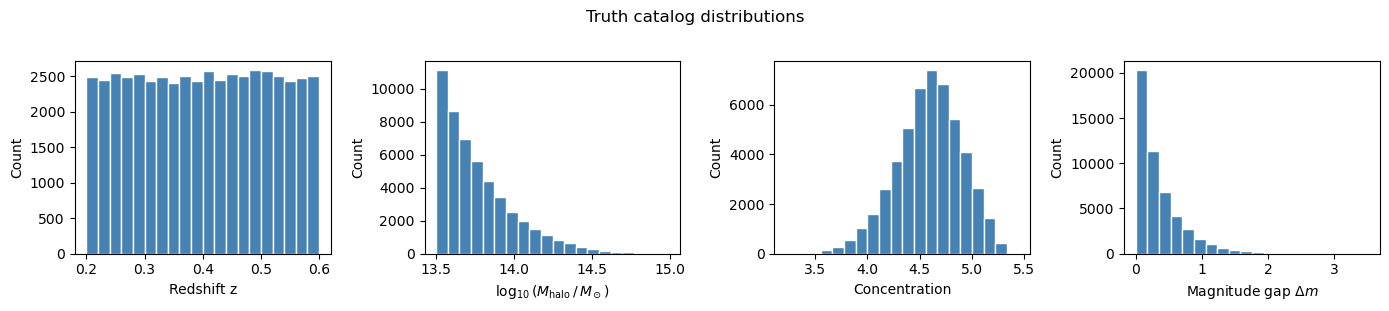

In [4]:
# Quick look at the truth distributions
fig, axes = plt.subplots(1, 4, figsize=(14, 3))

axes[0].hist(truth['z'], bins=20, color='steelblue', edgecolor='white')
axes[0].set_xlabel('Redshift z')

axes[1].hist(np.log10(truth['M_halo']), bins=20, color='steelblue', edgecolor='white')
axes[1].set_xlabel(r'$\log_{10}(M_{\rm halo}\,/\,M_\odot)$')

axes[2].hist(truth['concentration'], bins=20, color='steelblue', edgecolor='white')
axes[2].set_xlabel('Concentration')

dm = truth['delta_m']
axes[3].hist(dm[~np.isnan(dm)], bins=20, color='steelblue', edgecolor='white')
axes[3].set_xlabel(r'Magnitude gap $\Delta m$')

for ax in axes:
    ax.set_ylabel('Count')
plt.suptitle('Truth catalog distributions', y=1.02)
plt.tight_layout()
plt.show()

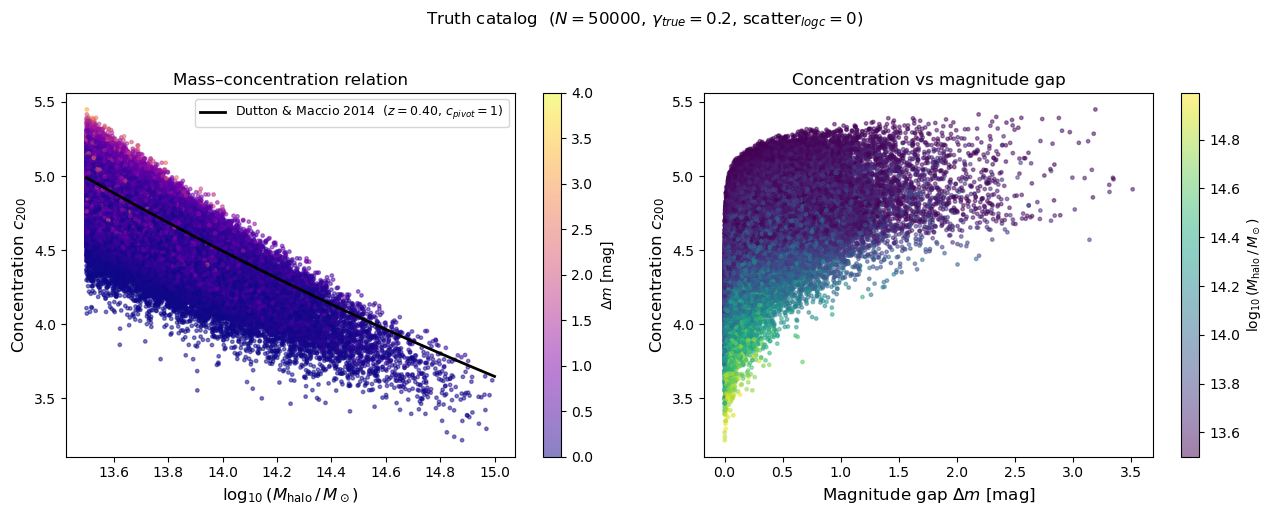

In [5]:
from destacking.relations import c_DuttonMaccio

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# --- Panel 1: M–c relation ---
ax = axes[0]
sc = ax.scatter(
    np.log10(truth['M_halo']), truth['concentration'],
    c=truth['delta_m'], cmap='plasma', s=6, alpha=0.5, vmin=0, vmax=4,
    rasterized=True,
)
plt.colorbar(sc, ax=ax, label=r'$\Delta m$ [mag]')

z_med = float(np.median(truth['z']))
M_curve = np.logspace(13.5, 15.0, 200)
C_curve = c_DuttonMaccio(z_med * np.ones(200), M_curve)
ax.plot(np.log10(M_curve), C_curve, 'k-', lw=2,
        label=rf'Dutton & Maccio 2014  ($z={z_med:.2f}$, $c_{{pivot}}=1$)')

ax.set_xlabel(r'$\log_{10}(M_{\rm halo}\,/\,M_\odot)$', fontsize=12)
ax.set_ylabel(r'Concentration $c_{200}$', fontsize=12)
ax.set_title('Mass–concentration relation', fontsize=12)
ax.legend(fontsize=9)

# --- Panel 2: c vs Δm ---
ax = axes[1]
sc2 = ax.scatter(
    truth['delta_m'], truth['concentration'],
    c=np.log10(truth['M_halo']), cmap='viridis', s=6, alpha=0.5,
    rasterized=True,
)
plt.colorbar(sc2, ax=ax, label=r'$\log_{10}(M_{\rm halo}\,/\,M_\odot)$')

ax.set_xlabel(r'Magnitude gap $\Delta m$ [mag]', fontsize=12)
ax.set_ylabel(r'Concentration $c_{200}$', fontsize=12)
ax.set_title(r'Concentration vs magnitude gap', fontsize=12)

plt.suptitle(
    rf'Truth catalog  ($N={N_CLUSTERS}$, $\gamma_{{true}}={TRUE_GAMMA}$, scatter$_{{logc}}=0$)',
    y=1.02, fontsize=12,
)
plt.tight_layout()
plt.show()

## 2 — Triaxial shapes and projected ellipses

Each cluster is assigned a random CDM-like triaxial shape and a random isotropic
line-of-sight direction.  `project_ellipsoid` computes the Schur complement of the
3D shape matrix to obtain the projected semi-axes (q_maj, q_min) and position angle pa.

Projecting triaxial ellipsoids...
Projected axis ratio q_min/q_maj:  median=0.69, range [0.30, 1.00]


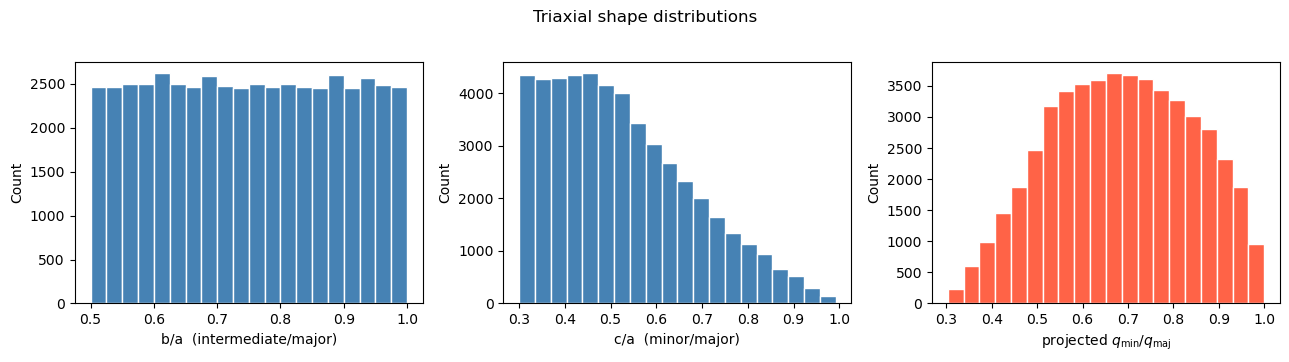

In [6]:
rng_tri = np.random.default_rng(SEED + 10)

# Virial radius for each cluster (used as major-axis scale)
r_vir_vals = np.array([r_vir(float(z), float(M))
                        for z, M in zip(truth['z'], truth['M_halo'])])

# CDM-like axis ratios: b/a ∈ (0.5, 1),  c/a ∈ (0.3, b/a)
q_ba = rng_tri.uniform(0.5, 1.0, N_CLUSTERS)
q_ca = rng_tri.uniform(0.3, q_ba)   # ensures c/a ≤ b/a element-wise

# Isotropic random line-of-sight directions: cos(θ) ~ U(0,1), φ ~ U(0,2π)
theta_los_arr = np.arccos(rng_tri.uniform(0.0, 1.0, N_CLUSTERS))
phi_los_arr   = rng_tri.uniform(0.0, 2 * np.pi, N_CLUSTERS)

# Project each 3D ellipsoid → projected sky ellipse
print("Projecting triaxial ellipsoids...")
q_maj_arr = np.zeros(N_CLUSTERS)
q_min_arr = np.zeros(N_CLUSTERS)
pa_arr    = np.zeros(N_CLUSTERS)
for i in range(N_CLUSTERS):
    a = r_vir_vals[i]
    b, c = q_ba[i] * a, q_ca[i] * a
    q_maj_arr[i], q_min_arr[i], pa_arr[i] = project_ellipsoid(
        a, b, c, theta_los_arr[i], phi_los_arr[i]
    )

print(f"Projected axis ratio q_min/q_maj:  "
      f"median={np.median(q_min_arr/q_maj_arr):.2f}, "
      f"range [{(q_min_arr/q_maj_arr).min():.2f}, {(q_min_arr/q_maj_arr).max():.2f}]")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
axes[0].hist(q_ba, bins=20, color='steelblue', edgecolor='white')
axes[0].set_xlabel('b/a  (intermediate/major)')
axes[1].hist(q_ca, bins=20, color='steelblue', edgecolor='white')
axes[1].set_xlabel('c/a  (minor/major)')
axes[2].hist(q_min_arr / q_maj_arr, bins=20, color='tomato', edgecolor='white')
axes[2].set_xlabel('projected $q_{\\rm min}/q_{\\rm maj}$')
for ax in axes: ax.set_ylabel('Count')
plt.suptitle('Triaxial shape distributions', y=1.02)
plt.tight_layout(); plt.show()

## 3 — Simulate triaxial NFW lensing measurements

For each cluster:
1. Draw fresh intrinsic shapes from `GPriorBA(σ=0.25)` and inject them into the base catalog.
2. Apply the cluster's triaxial NFW shear with `apply_triaxial_NFW_shear_region` from `xlensing.sims`.
3. Reorder columns to the metacal format expected by `metacal_cluster_lensing`.
4. Measure per-galaxy lensing quantities with `metacal_cluster_lensing` from `xlensing.data`.
5. Bin into ΔΣ(R) with `signal` from `xlensing.data`; assign diagonal shape-noise covariance.
   Empty bins receive the noise floor so they are effectively excluded from the likelihood.

The **cluster observables** (z, Λ, Δm) come from `make_test_data` (Lambda sampling only).
The fitting model is still **spherical NFW** — any recovery bias is due to triaxiality.

In [7]:
# ── Cluster observable table (z, Lambda, delta_m) — use make_test_data for Lambda sampling ──
cluster_obs, _, _ = make_test_data(truth, RADII, fractional_noise=0.2, seed=SEED + 1)

print(f'Observable table: {cluster_obs.colnames}')
print(f'Richness range:   {cluster_obs["Lambda"].min():.1f} – {cluster_obs["Lambda"].max():.1f}')
cluster_obs[:5]

Observable table: ['z', 'Lambda', 'delta_m']
Richness range:   1.0 – 95.0


z,Lambda,delta_m
float64,float64,float64
0.5095824194223852,21.0,0.08430557778520738
0.3755513759008209,12.0,0.29011146522575926
0.5434391679645529,13.0,0.5747491512792283
0.47894721162374554,11.0,0.07489569006201846
0.23767093915505982,6.0,0.020948997768123187


In [8]:
# Shared background galaxy field — positions/z fixed; shapes drawn fresh per cluster
# Output columns from make_simple_random_cat: [RA, DEC, z, e1, e2, R11, R12, R21, R22, W]
rng_base = np.random.default_rng(99)
base_cat = make_simple_random_cat(DENSITY, WIDTH_RAD, Z_SRC_RANGE, shape_noise=0.0, seed=0).T
N_GALS   = len(base_cat)

# Replace R11/R22 with a lognormal-size-based metacal response; off-diagonals stay 0
sizes  = rng_base.lognormal(mean=np.log(0.5), sigma=0.5, size=N_GALS)
R_RESP = np.clip(1.0 - (sizes / 1.5) ** 2, 0.05, 0.99)
base_cat[:, 5] = R_RESP   # R11
base_cat[:, 6] = 0.0      # R12
base_cat[:, 7] = 0.0      # R21
base_cat[:, 8] = R_RESP   # R22

print(f"Source field: {N_GALS} galaxies, half-width {WIDTH_RAD} rad")

Source field: 12764 galaxies, half-width 0.006 rad


In [9]:
%%time
from tqdm.auto import tqdm
import multiprocess as mp
from scipy.interpolate import interp1d
import xlensing.cosmo as _xlc
import xlensing.sims as _xlsims

# ── 1. Replace slow scipy-quad DA with a comoving-distance spline ──────────
# angular_diameter_distance_z1z2 invokes scipy.integrate.quad per element;
# for a flat cosmology D_A(z1,z2) = (chi(z2)-chi(z1))/(1+z2).
# One vectorised comoving_distance call builds the spline, then every DA
# evaluation is a cheap O(N) linear interpolation.
_z_tab    = np.linspace(0.0, 3.0, 5000)
_chi_tab  = _xlc.cosmology.comoving_distance(_z_tab).value   # single vectorised call
_chi_of_z = interp1d(_z_tab, _chi_tab, kind='linear',
                     bounds_error=False, fill_value='extrapolate')

def _DA_fast(z1, z2):
    """D_A(z1,z2) in Mpc via chi(z) spline — ~1000× faster than scipy.quad."""
    z2_a = np.atleast_1d(np.asarray(z2, dtype=float))
    res  = (_chi_of_z(z2_a) - float(_chi_of_z(float(z1)))) / (1.0 + z2_a)
    return float(res[0]) if np.ndim(z2) == 0 else res

# Patch both namespaces before forking the Pool so workers inherit the fast version:
#   data.py uses cosmo.DA(...)  → patch xlensing.cosmo.DA
#   sims.py imported DA at module level → patch xlensing.sims.DA
_xlc.DA    = _DA_fast
_xlsims.DA = _DA_fast

# ── 2. Per-cluster worker ───────────────────────────────────────────────────
def _process_cluster(i):
    z_i = float(truth['z'][i])
    M_i = float(truth['M_halo'][i])
    c_i = float(truth['concentration'][i])
    a_i = r_vir_vals[i]

    # Deterministic per-cluster shape noise
    rng_i  = np.random.default_rng(1000 + i)
    sp_i   = ngmix.priors.shape.GPriorBA(sigma=SHAPE_NOISE, rng=rng_i)
    e1, e2 = sp_i.sample2d(N_GALS)

    gal_i = base_cat.copy()
    gal_i[:, 3] = e1
    gal_i[:, 4] = e2

    # Pre-filter to the metacal background cut before shear injection.
    # z > 1.1*z_i + 0.2 implies z > z_i, so apply_triaxial's internal bg_mask
    # is trivially all-True — no redundant work, ~½ the array size.
    mc_mask = gal_i[:, 2] > 1.1 * z_i + 0.2
    gal_mc  = gal_i[mc_mask]
    if len(gal_mc) < 20:
        return i, None, None

    cluster_arr = [0., 0., z_i, M_i, c_i,
                   a_i, q_ba[i] * a_i, q_ca[i] * a_i,
                   theta_los_arr[i], phi_los_arr[i]]
    gal_sheared = apply_triaxial_NFW_shear_region(cluster_arr, gal_mc)

    # Reorder to metacal format: [RA, DEC, z, E1, E2, W, R11, R12, R21, R22]
    sources_mc = gal_sheared[:, [0, 1, 2, 3, 4, 9, 5, 6, 7, 8]]
    radius_mpc = WIDTH_RAD * _DA_fast(0, z_i)
    bg = metacal_cluster_lensing((0., 0., z_i), sources_mc.T, radius_mpc)
    if bg['Count'] < 20:
        return i, None, None

    stake = np.array([
        bg['Critical Density'], bg['Tangential Shear'], bg['Cross Shear'],
        bg['Weights'], bg['Radial Distance'], bg['Mult. Bias'],
    ])
    sig_t, _ = signal(stake, bin_limits)
    dv = np.nan_to_num(sig_t, nan=0.0)

    R      = bg['Radial Distance']
    in_bin = (R[:, None] > bin_limits[:, 0]) & (R[:, None] < bin_limits[:, 1])
    cov_d  = np.full(N_BINS, NOISE_FLOOR_COV)
    for b in range(N_BINS):
        m   = in_bin[:, b]
        n_b = m.sum()
        if n_b >= 5:
            cov_d[b] = (SHAPE_NOISE * bg['Critical Density'][m].mean() / np.sqrt(n_b)) ** 2

    return i, dv, cov_d

# ── 3. Output arrays ────────────────────────────────────────────────────────
N_BINS       = len(RADII)
data_vectors = np.zeros((N_CLUSTERS, N_BINS))
cov_matrices = np.full((N_CLUSTERS, N_BINS, N_BINS), 0.)
for i in range(N_CLUSTERS):
    np.fill_diagonal(cov_matrices[i], NOISE_FLOOR_COV)

# ── 4. Parallel dispatch ─────────────────────────────────────────────────────
# Fork-based Pool inherits the patched DA and all closed-over arrays via CoW.
N_WORKERS = 15
with mp.Pool(N_WORKERS) as pool:
    for idx, dv, cov_d in tqdm(
        pool.imap(_process_cluster, range(N_CLUSTERS), chunksize=20),
        total=N_CLUSTERS, desc='Triaxial lensing',
    ):
        if dv is not None:
            data_vectors[idx] = dv
            np.fill_diagonal(cov_matrices[idx], cov_d)

print(f"\nData generated. Non-empty bins per cluster: "
      f"{(np.diagonal(cov_matrices, axis1=1, axis2=2) < NOISE_FLOOR_COV).sum(1).mean():.1f} / {N_BINS}")

Triaxial lensing:   0%|          | 0/50000 [00:00<?, ?it/s]


Data generated. Non-empty bins per cluster: 5.3 / 8
CPU times: user 4.49 s, sys: 1.35 s, total: 5.83 s
Wall time: 4min 43s


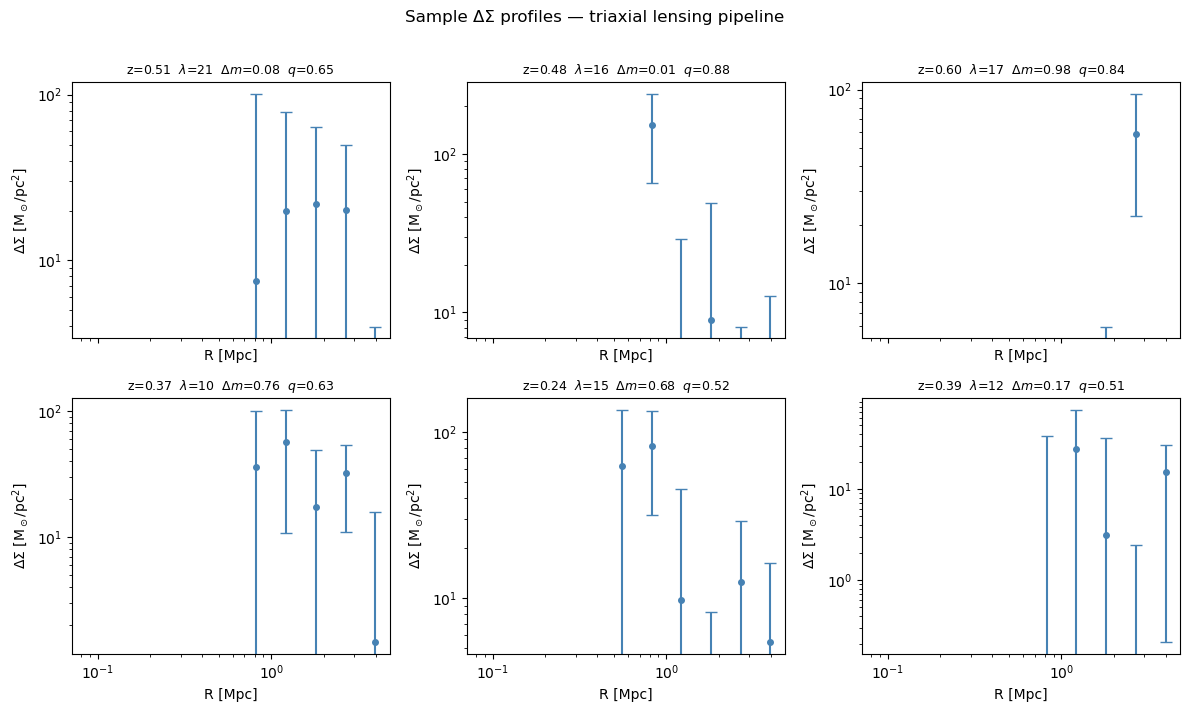

In [10]:
# Sanity check — plot six example profiles
idx = np.round(np.linspace(0, N_CLUSTERS - 1, 6)).astype(int)
fig, axes = plt.subplots(2, 3, figsize=(12, 7), sharex=True)

for ax, i in zip(axes.ravel(), idx):
    errs = np.sqrt(np.diag(cov_matrices[i]))
    # Only show bins with real data (not the noise-floor-filled ones)
    real_mask = errs < np.sqrt(NOISE_FLOOR_COV)
    ax.errorbar(RADII[real_mask], data_vectors[i, real_mask], yerr=errs[real_mask],
                fmt='o', markersize=4, capsize=4, color='steelblue')
    ax.set_xscale('log')
    ax.set_yscale('log')
    dm_str = f'{cluster_obs["delta_m"][i]:.2f}' if np.isfinite(cluster_obs['delta_m'][i]) else 'nan'
    ax.set_title(
        f'z={cluster_obs["z"][i]:.2f}  '
        rf'$\lambda$={cluster_obs["Lambda"][i]:.0f}  '
        rf'$\Delta m$={dm_str}  '
        rf'$q$={q_min_arr[i]/q_maj_arr[i]:.2f}',
        fontsize=9,
    )
    ax.set_xlabel('R [Mpc]')
    ax.set_ylabel(r'$\Delta\Sigma$ [M$_\odot$/pc$^2$]')

plt.suptitle('Sample ΔΣ profiles — triaxial lensing pipeline', y=1.01)
plt.tight_layout()
plt.show()

## 4 — Run the sampler

Fits γ and log_M_norm jointly against the triaxially-simulated ΔΣ profiles.
The forward model uses spherical NFW — any bias here is due to triaxiality.

In [11]:
sampler = run_sampler(
    cluster_obs,
    data_vectors,
    cov_matrices,
    RADII,
    gamma_range=(-1.0, 1.0),
    n_live=500,
    verbose=True,
    pool=15,
)

Starting the nautilus sampler...
Please report issues at github.com/johannesulf/nautilus.
Status    | Bounds | Ellipses | Networks | Calls    | f_live | N_eff | log Z    
Finished  | 14     | 1        | 4        | 14385    | N/A    | 10011 | -2256993.


## 5 — Posterior and recovery plot

In [12]:
points, log_w, log_l = sampler.posterior()
gamma_samples = points[:, 0]
weights       = np.exp(log_w - log_w.max())   # numerically stable normalisation
weights      /= weights.sum()


def weighted_quantile(values, quantiles, weights):
    """Weighted quantiles via sorted cumulative sum."""
    sorter = np.argsort(values)
    v = values[sorter]
    w = weights[sorter]
    cumw = np.cumsum(w) / np.sum(w)
    return np.interp(quantiles, cumw, v)


glo, gmd, ghi = weighted_quantile(gamma_samples, [0.16, 0.50, 0.84], weights)
print(f'True γ  : {TRUE_GAMMA}')
print(f'Recovered: {gmd:.3f}  −{gmd - glo:.3f}  +{ghi - gmd:.3f}')

True γ  : 0.2
Recovered: 0.291  −0.068  +0.068


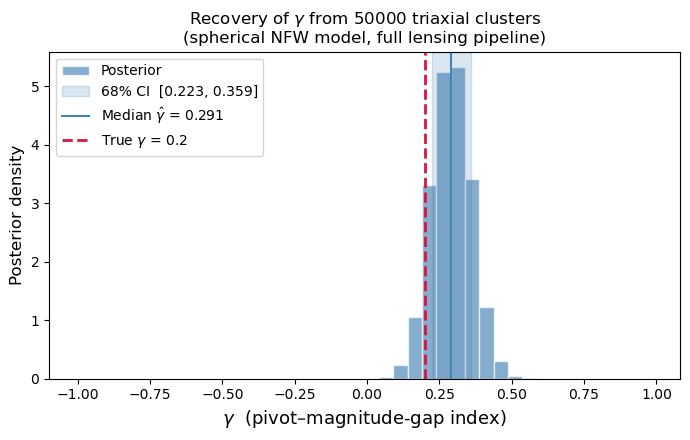


Bias relative to 68% CI width: 1.34σ  (consistent with true γ)


In [13]:
fig, ax = plt.subplots(figsize=(7, 4.5))

ax.hist(
    gamma_samples, weights=weights, bins=40, density=True,
    color='steelblue', alpha=0.65, edgecolor='white', label='Posterior',
)
ax.axvspan(
    glo, ghi, alpha=0.20, color='steelblue',
    label=rf'68% CI  [{glo:.3f}, {ghi:.3f}]',
)
ax.axvline(gmd,       color='steelblue', lw=1.5, ls='-',
           label=rf'Median $\hat{{\gamma}}$ = {gmd:.3f}')
ax.axvline(TRUE_GAMMA, color='crimson',   lw=2.0, ls='--',
           label=rf'True $\gamma$ = {TRUE_GAMMA}')

ax.set_xlabel(r'$\gamma$  (pivot–magnitude-gap index)', fontsize=13)
ax.set_ylabel('Posterior density', fontsize=12)
ax.set_title(
    rf'Recovery of $\gamma$ from {N_CLUSTERS} triaxial clusters'
    '\n(spherical NFW model, full lensing pipeline)',
    fontsize=12,
)
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig(f'gamma_posterior_triaxial_{TRUE_GAMMA}.png', dpi=150)
plt.show()

bias = abs(gmd - TRUE_GAMMA) / ((ghi - glo) / 2)
print(f"\nBias relative to 68% CI width: {bias:.2f}σ"
      f"  ({'consistent' if bias < 2 else 'BIASED'} with true γ)")